# 05 · Evaluating the AI: when can a bank trust it?

No AI calls here: everything uses the saved results, so it's quick and free.
Run cells one at a time, top to bottom.

1. Load and join → 2. Headline: AI vs baseline → 3. Per-issue scores → 4. Where the AI gets confused → 5. Is its confidence honest? → 6. Human-in-the-loop routing → 7. Vulnerability → 8. Cost and speed → 9. Gold-set check (after you finish labelling)

In [7]:
# 1. Load and join everything
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

test = pd.read_csv("data/clean/test_1000.csv")
base = pd.read_csv("outputs/baseline_predictions.csv")[["complaint_id", "baseline_pred"]]
llm = pd.read_csv("outputs/llm_triage.csv").drop_duplicates("complaint_id")
llm["vulnerable"] = llm["vulnerable"].astype(str).str.lower().eq("true")

df = (test[["complaint_id", "issue", "narrative", "words"]]
      .merge(base, on="complaint_id")
      .merge(llm.rename(columns={"issue": "llm_pred"}), on="complaint_id"))
df["llm_correct"] = df["llm_pred"] == df["issue"]
df["base_correct"] = df["baseline_pred"] == df["issue"]
os.makedirs("outputs", exist_ok=True)
print("Complaints evaluated:", len(df))

Complaints evaluated: 1000


In [2]:
# 2. Headline: AI vs baseline vs guessing
majority = df["issue"].value_counts(normalize=True).iloc[0]
headline = pd.DataFrame({
    "model": ["Guess most common issue", "Baseline (TF-IDF + logistic regression)", "Gemini Flash-Lite (zero-shot)"],
    "accuracy_%": [majority * 100,
                   accuracy_score(df["issue"], df["baseline_pred"]) * 100,
                   accuracy_score(df["issue"], df["llm_pred"]) * 100],
    "macro_F1_%": [np.nan,
                   f1_score(df["issue"], df["baseline_pred"], average="macro") * 100,
                   f1_score(df["issue"], df["llm_pred"], average="macro") * 100],
    "training_examples_used": [0, 101_000, 0]}).round(1)
headline.to_csv("outputs/eval_headline.csv", index=False)
headline

,model,accuracy_%,macro_F1_%,training_examples_used
0,Guess most common issue,26.4,NaN,0
1,Baseline (TF-IDF + logistic regression),70.6,63.8,101000
2,Gemini Flash-Lite (zero-shot),59.4,50.7,0


In [3]:
# 3. Per-issue scores: where does each model win?
labels = sorted(df["issue"].unique())
pb, rb, fb, n = precision_recall_fscore_support(df["issue"], df["baseline_pred"], labels=labels, zero_division=0)
pl, rl, fl, _ = precision_recall_fscore_support(df["issue"], df["llm_pred"], labels=labels, zero_division=0)
per_issue = pd.DataFrame({"issue": labels, "complaints": n,
                          "baseline_recall": rb, "llm_recall": rl,
                          "baseline_F1": fb, "llm_F1": fl}).round(2)
per_issue["F1_winner"] = np.where(per_issue["llm_F1"] > per_issue["baseline_F1"], "AI", "Baseline")
per_issue.to_csv("outputs/eval_per_issue.csv", index=False)
per_issue.sort_values("complaints", ascending=False)

,issue,complaints,baseline_recall,llm_recall,baseline_F1,llm_F1,F1_winner
8,Problem with a purchase shown on your statement,264,0.84,0.81,0.82,0.85,AI
5,"Other features, terms, or problems",117,0.46,0.29,0.50,0.39,Baseline
3,Getting a credit card,114,0.83,0.63,0.78,0.68,Baseline
2,Fees or interest,111,0.79,0.67,0.74,0.66,Baseline
7,Problem with a company's investigation into an...,87,0.71,0.01,0.76,0.02,Baseline
1,Closing your account,76,0.72,0.72,0.72,0.64,Baseline
4,Incorrect information on your report,67,0.51,0.75,0.54,0.39,Baseline
6,Problem when making payments,59,0.64,0.44,0.62,0.45,Baseline
0,"Advertising and marketing, including promotion...",49,0.63,0.65,0.66,0.65,Baseline
10,Trouble using your card,43,0.53,0.65,0.57,0.52,Baseline


In [4]:
# 4. Where does the AI get confused? (true label -> AI's label, most common mistakes)
mistakes = (df[~df["llm_correct"]]
            .groupby(["issue", "llm_pred"]).size()
            .sort_values(ascending=False).head(10)
            .reset_index(name="count"))
mistakes["share_of_all_AI_errors_%"] = (mistakes["count"] / (~df["llm_correct"]).sum() * 100).round(1)
mistakes

,issue,llm_pred,count,share_of_all_AI_errors_%
0,Problem with a company's investigation into an...,Incorrect information on your report,75,18.5
1,Getting a credit card,Incorrect information on your report,30,7.4
2,"Other features, terms, or problems",Trouble using your card,19,4.7
3,"Other features, terms, or problems",Problem with a purchase shown on your statement,18,4.4
4,"Other features, terms, or problems",Closing your account,15,3.7
5,Problem with a purchase shown on your statement,Incorrect information on your report,12,3.0
6,"Other features, terms, or problems","Advertising and marketing, including promotion...",10,2.5
7,Fees or interest,Problem when making payments,9,2.2
8,Problem with a purchase shown on your statement,Fees or interest,9,2.2
9,Problem with a purchase shown on your statement,Problem when making payments,9,2.2


In [5]:
# 5. Is the AI's confidence honest? (calibration)
#    If the AI says 0.9, it should be right about 90% of the time.
bins = [0, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0001]
df["conf_band"] = pd.cut(df["confidence"], bins, right=False)
calib = df.groupby("conf_band", observed=True).agg(
    complaints=("llm_correct", "size"),
    avg_stated_confidence=("confidence", "mean"),
    actual_accuracy=("llm_correct", "mean")).round(3)
calib["gap_(overconfidence)"] = (calib["avg_stated_confidence"] - calib["actual_accuracy"]).round(3)
print(f"Average stated confidence: {df['confidence'].mean():.2f} | actual accuracy: {df['llm_correct'].mean():.2f}")
calib

Average stated confidence: 0.92 | actual accuracy: 0.59


,complaints,avg_stated_confidence,actual_accuracy,gap_(overconfidence)
conf_band,,,,
"[0.0, 0.6)",1,0.500,0.000,0.500
"[0.7, 0.8)",2,0.700,0.500,0.200
"[0.8, 0.9)",106,0.830,0.349,0.481
"[0.9, 0.95)",457,0.900,0.545,0.355
"[0.95, 1.0)",434,0.963,0.707,0.256


When AI and baseline AGREE (65.0% of complaints): 79.1% correct
When they DISAGREE (35.0%): AI 22.9% | baseline 54.9% correct


OSError: [Errno 22] Invalid argument: 'outputs/human_in_loop.png'

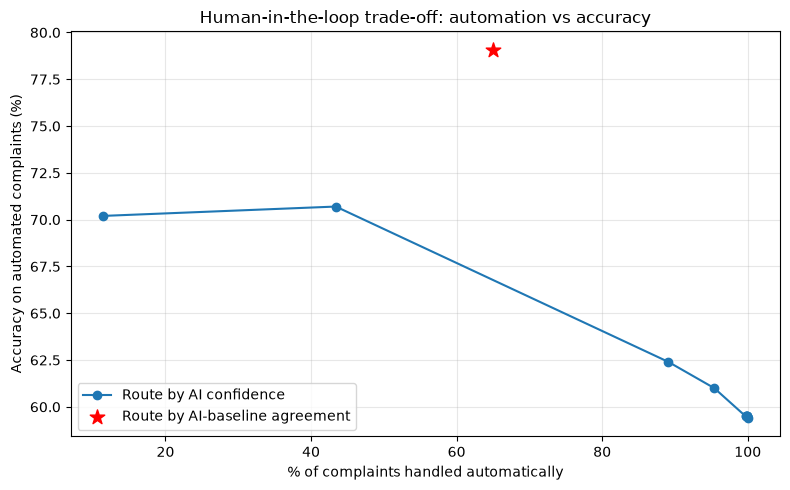

In [9]:
# 6. Human-in-the-loop: which complaints can be automated, and which go to a person?
#    Two possible 'trust signals':
#    (a) the AI's own confidence, (b) whether the AI and the baseline AGREE.
rows = []
for t in np.arange(0.50, 1.00, 0.05):
    auto = df["confidence"] >= t
    rows.append({"rule": f"AI confidence >= {t:.2f}", "automated_%": auto.mean() * 100,
                 "accuracy_on_automated_%": df.loc[auto, "llm_correct"].mean() * 100 if auto.any() else np.nan})
agree = df["llm_pred"] == df["baseline_pred"]
rows.append({"rule": "AI and baseline agree", "automated_%": agree.mean() * 100,
             "accuracy_on_automated_%": df.loc[agree, "llm_correct"].mean() * 100})
hitl = pd.DataFrame(rows).round(1)
hitl.to_csv("outputs/eval_human_in_loop.csv", index=False)

print(f"When AI and baseline AGREE ({agree.mean()*100:.1f}% of complaints): {df.loc[agree, 'llm_correct'].mean()*100:.1f}% correct")
print(f"When they DISAGREE ({(~agree).mean()*100:.1f}%): AI {df.loc[~agree, 'llm_correct'].mean()*100:.1f}% | baseline {df.loc[~agree, 'base_correct'].mean()*100:.1f}% correct")

conf_rows = hitl[hitl["rule"].str.startswith("AI confidence")]
plt.figure(figsize=(8, 5))
plt.plot(conf_rows["automated_%"], conf_rows["accuracy_on_automated_%"], marker="o", label="Route by AI confidence")
plt.scatter(agree.mean() * 100, df.loc[agree, "llm_correct"].mean() * 100, s=120, marker="*", color="red", label="Route by AI-baseline agreement")
plt.xlabel("% of complaints handled automatically")
plt.ylabel("Accuracy on automated complaints (%)")
plt.title("Human-in-the-loop trade-off: automation vs accuracy")
plt.legend(loc="lower left"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("outputs/human_in_loop.png", dpi=150); plt.show()
hitl

In [7]:
# 7. Vulnerability: does the AI flag the right kind of complaints?
#    No human labels yet (see cell 9), but a sense-check: 'Struggling to pay your bill' complaints
#    should be flagged far more often than e.g. 'Advertising and marketing'.
vuln = (df.groupby("issue").agg(complaints=("vulnerable", "size"), flagged_vulnerable_pct=("vulnerable", "mean"),
                                 baseline_recall=("base_correct", "mean"))
        .assign(flagged_vulnerable_pct=lambda d: (d["flagged_vulnerable_pct"] * 100).round(1),
                baseline_recall=lambda d: (d["baseline_recall"] * 100).round(1))
        .sort_values("flagged_vulnerable_pct", ascending=False))

stp = df[df["issue"] == "Struggling to pay your bill"]
print(f"'Struggling to pay' complaints: {len(stp)} | baseline labelled correctly: {stp['base_correct'].mean()*100:.0f}% "
      f"| AI flagged as vulnerable: {stp['vulnerable'].mean()*100:.0f}%")
print("\nMost common vulnerability reasons given by the AI:")
print(df.loc[df["vulnerable"], "vulnerability_reason"].str.lower().str.strip().value_counts().head(8))
vuln.to_csv("outputs/eval_vulnerability_by_issue.csv")
vuln

'Struggling to pay' complaints: 13 | baseline labelled correctly: 23% | AI flagged as vulnerable: 77%

Most common vulnerability reasons given by the AI:
vulnerability_reason
financial hardship                     42
health                                 29
resilience                             21
life events                            16
capability                              6
mental health                           5
bereavement                             3
financial hardship and debt worries     3
Name: count, dtype: int64


,complaints,flagged_vulnerable_pct,baseline_recall
issue,,,
Struggling to pay your bill,13,76.9,23.1
Problem when making payments,59,25.4,64.4
Trouble using your card,43,23.3,53.5
Fees or interest,111,22.5,79.3
Incorrect information on your report,67,16.4,50.7
"Other features, terms, or problems",117,16.2,46.2
Closing your account,76,15.8,72.4
Problem with a company's investigation into an existing problem,87,14.9,71.3
Problem with a purchase shown on your statement,264,14.0,84.5


In [8]:
# 8. Cost and speed
#    Fill in the CURRENT paid price per 1 million tokens for your model from Google's Gemini API pricing page.
#    (We used the free tier, so our real cost was £0 - this estimates the cost at scale.)
PRICE_IN_PER_M_USD = 0.25    # <- check and update from the pricing page
PRICE_OUT_PER_M_USD = 1.50   # <- check and update from the pricing page
USD_TO_GBP = 0.78            # <- check today's rate

tin, tout = llm["in_tokens_per_complaint"].mean(), llm["out_tokens_per_complaint"].mean()
cost_per_1000_gbp = (tin * PRICE_IN_PER_M_USD + tout * PRICE_OUT_PER_M_USD) / 1e6 * 1000 * USD_TO_GBP
secs = llm["seconds_per_complaint"].mean()
HUMAN_MINUTES_PER_COMPLAINT = 3   # assumption: read ~157 words + record triage fields

print(f"Tokens per complaint: {tin:.0f} in / {tout:.0f} out")
print(f"Estimated AI cost per 1,000 complaints: £{cost_per_1000_gbp:.2f}")
print(f"AI time per 1,000 complaints: {secs*1000/60:.0f} minutes (batched, one process)")
print(f"Human time per 1,000 complaints: {HUMAN_MINUTES_PER_COMPLAINT*1000/60:.0f} hours (at {HUMAN_MINUTES_PER_COMPLAINT} min each)")

Tokens per complaint: 406 in / 107 out
Estimated AI cost per 1,000 complaints: £0.20
AI time per 1,000 complaints: 17 minutes (batched, one process)
Human time per 1,000 complaints: 50 hours (at 3 min each)


In [5]:
# 9. Gold-set check: run AFTER you finish labelling data/clean/gold_100_labelled.xlsx
#    Columns needed: complaint_id, my_vulnerable (Yes/No), my_outcome
from sklearn.metrics import cohen_kappa_score, confusion_matrix

GOLD = "data/clean/gold_100_labelled_completed.xlsx"
if not os.path.exists(GOLD):
    print("Gold labels not found yet - finish labelling, save as", GOLD, "and re-run this cell.")
else:
    g = pd.read_excel(GOLD)[["complaint_id", "my_vulnerable", "my_outcome"]].dropna(subset=["my_vulnerable"])
    g["my_vulnerable"] = g["my_vulnerable"].astype(str).str.strip().str.lower().isin(["yes", "y", "true", "1"])
    g = g.merge(df[["complaint_id", "vulnerable", "consumer_duty_outcome"]], on="complaint_id")
    tn, fp, fn, tp = confusion_matrix(g["my_vulnerable"], g["vulnerable"], labels=[False, True]).ravel()
    print(f"Gold complaints labelled: {len(g)} | you marked vulnerable: {g['my_vulnerable'].sum()}")
    print(f"Vulnerability - AI caught {tp} of {tp+fn} you flagged (recall {tp/max(tp+fn,1)*100:.0f}%), "
          f"{fp} false alarms (precision {tp/max(tp+fp,1)*100:.0f}%)")
    g2 = g.dropna(subset=["my_outcome"])
    agree_out = (g2["my_outcome"].str.strip().str.lower() == g2["consumer_duty_outcome"].str.lower()).mean()
    print(f"Consumer Duty outcome - AI agreed with you on {agree_out*100:.0f}% "
          f"(Cohen's kappa {cohen_kappa_score(g2['my_outcome'].str.strip().str.lower(), g2['consumer_duty_outcome'].str.lower()):.2f})")
    g.to_csv("outputs/eval_gold.csv", index=False)

Gold complaints labelled: 100 | you marked vulnerable: 12
Vulnerability - AI caught 12 of 12 you flagged (recall 100%), 8 false alarms (precision 60%)
Consumer Duty outcome - AI agreed with you on 74% (Cohen's kappa 0.45)


In [6]:
extra = pd.read_csv("data/clean/test_1000.csv", usecols=["complaint_id", "company", "date_received"])
extra["month"] = pd.to_datetime(extra["date_received"], format="mixed", utc=True).dt.strftime("%Y-%m")

pbi = df.merge(extra[["complaint_id", "company", "month"]], on="complaint_id")
pbi["route"] = np.where(pbi["llm_pred"] == pbi["baseline_pred"], "Automate (models agree)", "Human review")
pbi = pbi[["complaint_id", "month", "company", "issue", "baseline_pred", "llm_pred", "consumer_duty_outcome",
           "vulnerable", "vulnerability_reason", "severity", "confidence", "summary",
           "llm_correct", "base_correct", "route"]]
pbi.to_csv("outputs/pbi_triage.csv", index=False)
print(pbi.shape)
pbi["route"].value_counts()

(1000, 15)


route
Automate (models agree)    650
Human review               350
Name: count, dtype: int64